# Getting started with GLoBES.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/GLoBES.jl/blob/main/notebooks/01_getting_started.ipynb)

GLoBES.jl is a Julia port of [GLoBES](https://www.mpi-hd.mpg.de/personalhomes/globes/), the General Long Baseline Experiment Simulator. It reads AEDL experiment files and computes oscillation probabilities, event rates and χ². It also handles models of new physics, written as Mathematica-style model files like those of SARAH.

On Colab, choose **Runtime → Change runtime type → Julia** first. Every function has one-line examples in its help: `?chi2`.

In [ ]:
# Install GLoBES.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if both are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add("Plots")

In [2]:
using GLoBES, Plots
examples = joinpath(pkgdir(GLoBES), "examples")   # experiment and model files that come with the package

"/root/.julia/packages/GLoBES/examples"

## Oscillation probabilities

Oscillation parameters are `OscParams`: angles in radians and mass splittings in eV².

In [3]:
truth = OscParams(θ12 = asin(sqrt(0.307)), θ13 = asin(sqrt(0.02203)), θ23 = asin(sqrt(0.572)), δ = deg2rad(198), Δm21 = 7.41e-5, Δm31 = 2.511e-3)

OscParams
  θ12 = 0.587252  (sin²θ12 = 0.307)
  θ13 = 0.148976  (sin²2θ13 = 0.0861787)
  θ23 = 0.857649  (sin²θ23 = 0.572)
  δ   = 3.45575  (1.1 π)
  Δm21 = 7.41e-05 eV²
  Δm31 = 0.002511 eV²
  ρ   = 1.0

In [4]:
probability(truth, :μ, :e; E = 2.5, L = 1300, ρ = 2.848)   # parameters, from, to; GeV, km, g/cm³

0.07894774057683097

In [5]:
probability(truth, :μ, :e; E = 2.5, L = 1300, ρ = 2.848, antineutrino = true)   # the same for antineutrinos

0.02644367086257538

The best fit of [NuFIT](http://www.nu-fit.org) is one line away. It downloads the NuFIT tables once, so it needs network access to nu-fit.org:

```julia
nufit_params("6.1"; ordering = :normal)
```

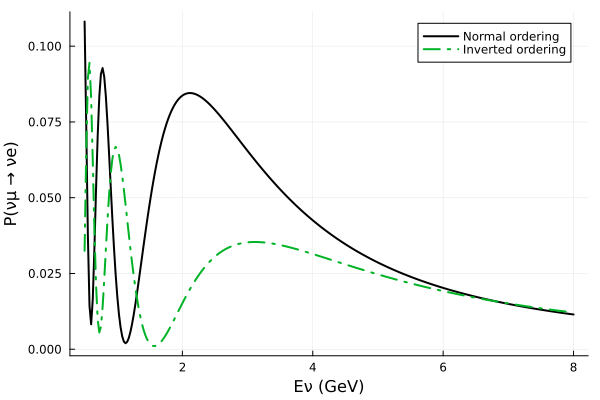

In [6]:
inverted = OscParams(truth; Δm31 = -2.498e-3)   # a copy with some parameters changed
plot_probability("Normal ordering" => truth, "Inverted ordering" => inverted; E = range(0.5, 8, 300), L = 1300, ρ = 2.848)

## An experiment: DUNE

`Experiment` loads an AEDL file. `dune_configuration()` gives the DUNE configuration of the Technical Design Report: its AEDL files come with the package, and its data tables are downloaded from arXiv the first time. It uses the correlated systematics of GLoBES 3.2.

In [7]:
dune = Experiment(dune_configuration())   # the first time, this downloads the data tables from arXiv

Experiment "DUNE_GLoBES" (/root/.julia/scratchspaces/367f8d2e-8d77-4eed-9bd4-73b32ac618fb/dune/DUNE_GLoBES.glb)
  baseline     1284.9 km
  target mass  40.0 kt
  energy bins  80 from 0 to 110 GeV
  channels     32
  rules        nue_app, nuebar_app, numu_dis, numubar_dis

In [8]:
rule_names(dune), baseline(dune), running_time(dune)

(["nue_app", "nuebar_app", "numu_dis", "numubar_dis"], 1284.9, 6.5)

In [9]:
simulate!(truth)   # the "data": event rates for the true parameters
[sum(event_rates(dune; rule = r).signal) for r in 1:4]   # signal events of each rule

4-element Vector{Float64}:
  2330.191410354472
   511.37294468627545
 20180.940372724363
 11810.09359011693

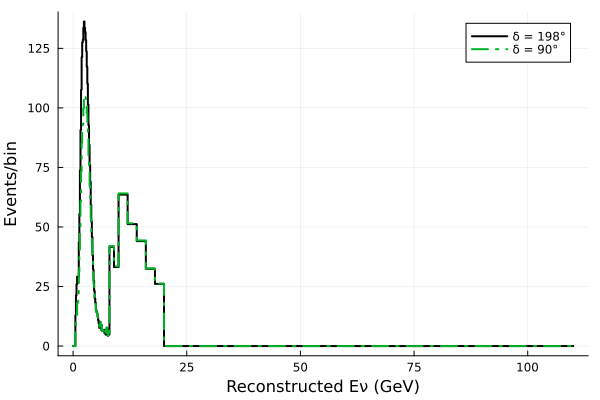

In [10]:
plot_events(dune, "δ = 198°" => truth, "δ = 90°" => OscParams(truth; δ = π / 2); rule = 1)

## χ²

`chi2(test)` is the Δχ² between the simulated data and the test parameters, minimised over the systematics. `chi2_scan` repeats it over a range of values, and `marginalize` also fits other parameters.

In [11]:
chi2(OscParams(truth; δ = 0)), chi2(OscParams(truth; δ = 0); systematics = false)   # CP conservation, with and without systematics

(105.77858812347603, 111.76739215809302)

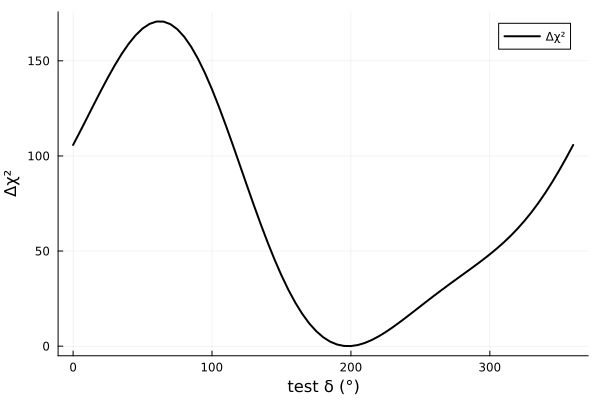

In [12]:
δs = range(0, 2π, 73)
plot_curves(rad2deg.(δs), "Δχ²" => chi2_scan(truth, :δ => δs); xlabel = "test δ (°)", ylabel = "Δχ²")

## Models of new physics

A model is described by a Mathematica-style file, written the way SARAH model files are: `Model`Name = ...;` and one ingredient per line, with a comment above each. Every ingredient you leave out keeps its default, the standard three-flavour oscillation in matter. This example adds Lorentz-invariance violation:

In [13]:
liv = model_from_string("""
    Model`Name = "LIV";

    (* Additional terms of the Hamiltonian. Each entry: {name, matrix in eV}; c E grows with the energy *)
    AdditionalTerms[[2]] = {LIV, c E Diag[{1, -1, 0}]};
    """; parameters = """
    (* Each entry: {name, {options}} *)
    ParameterDefinitions = {{c, {Value -> 0, LaTeX -> "c"}}};
    """)

OscillationModel "LIV"
  flavours:   e, mu, tau
  AdditionalTerms[LIV]        Times[c, E, Diag[{1, -1, 0}]]
  MixingMatrix                (default)
  MassSquared                 (default)
  MassHierarchy[NH]           (default)
  MassHierarchy[IH]           (default)
  AdditionalTerms[Matter]     (default)
  hierarchy:  Auto
  parameters: theta12, theta13, theta23, deltaCP, dm21, dm31, mlightest, c

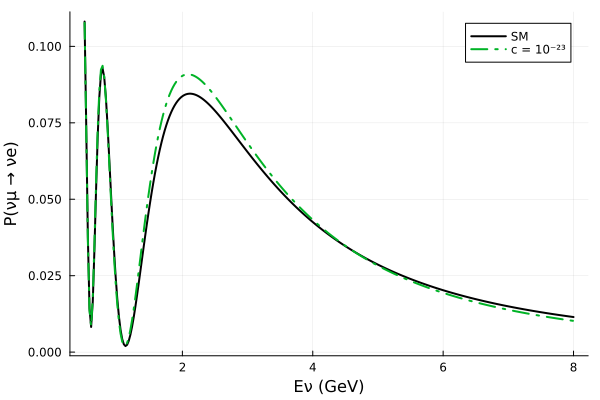

In [14]:
use_model!(liv)   # experiments now use the model's Hamiltonian
standard = OscParams(liv; theta12 = truth.θ12, theta13 = truth.θ13, theta23 = truth.θ23, deltaCP = truth.δ, dm21 = truth.Δm21, dm31 = truth.Δm31)
plot_probability("SM" => standard, "c = 10⁻²³" => OscParams(liv, standard; c = 1e-23); E = range(0.5, 8, 300), L = 1300, ρ = 2.848)

In [15]:
effective_parameters(liv, OscParams(liv, standard; c = 1e-23); E = 2.5, ρ = 2.848)   # mixing angles, phase and mass splittings in matter

OscParams
  θ12 = 0.0378777  (sin²θ12 = 0.00143403)
  θ13 = 0.209869  (sin²2θ13 = 0.166074)
  θ23 = 0.831754  (sin²θ23 = 0.54629)
  δ   = 0.427173  (0.136 π)
  Δm21 = -0.00067348 eV²
  Δm31 = 0.00179497 eV²
  ρ   = 1.0

Larger models live in a directory with a model file, `parameters.m` and a `Run.m` that lists what to calculate, plot and write to LaTeX. The scalar-NSI model in `examples/models/SNSI` is one; [02_scalar_NSI_and_decoherence_at_DUNE.ipynb](02_scalar_NSI_and_decoherence_at_DUNE.ipynb) uses it for DUNE.

In [16]:
snsi = load_model(joinpath(examples, "models", "SNSI"))
print(latex(snsi; Parameters = false, NuFit = false))   # the model as LaTeX

\section{The Scalar NSI with decoherence model}
Model by GLoBES.jl example.

Flavours: $\nu_e, \nu_\mu, \nu_\tau$ (3 states). Energies, masses and the Hamiltonian are in eV; $A = \sqrt{2} G_F N_e$ is the matter potential.

\subsection*{Effective Hamiltonian}
\begin{equation}
  H = \frac{1}{2E} M M^\dagger + H_{\mathrm{Matter}}
\end{equation}
For antineutrinos $H \to H^*$ with $A \to -A$.

\subsection*{Definitions}
\begin{align}
  \eta &= \begin{pmatrix} \eta_{ee} & \eta_{e\mu} e^{i \delta_{e\mu}} & \eta_{e\tau} e^{i \delta_{e\tau}} \\ \eta_{e\mu} e^{-i \delta_{e\mu}} & \eta_{\mu\mu} & \eta_{\mu\tau} e^{i \delta_{\mu\tau}} \\ \eta_{e\tau} e^{-i \delta_{e\tau}} & \eta_{\mu\tau} e^{-i \delta_{\mu\tau}} & \eta_{\tau\tau} \end{pmatrix} \\
  R_{12} &= R_{12}\left(\theta_{12}\right) \\
  R_{13} &= R_{13}\left(\theta_{13}\right) \\
  R_{23} &= R_{23}\left(\theta_{23}\right) \\
  U_\delta &= P_{3}\left(\delta_{\mathrm{CP}}\right)
\end{align}
\subsection*{Mixing matrix}
\begin{align}
  U &= R_{2

In [ ]:
standard_engine!()   # back to standard oscillations